<a href="https://colab.research.google.com/github/carolhr/detector-fraude/blob/master/detector_fraude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Explore (Análise Exploratória)

In [12]:
import pandas as pd
import numpy as np

# Carregar a base de dados
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

# Medir a proporção exata de fraudes
print(df['Class'].value_counts(normalize=True) * 100)


Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


2. Prepare (Engenharia de Features e Pré-processamento)

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Criar nova variável: Log do valor (somando 1 para evitar log(0))
df['log_amount'] = np.log1p(df['Amount'])

# Padronizar o tempo e o log do valor com StandardScaler
scaler = StandardScaler()
df['scaled_time'] = scaler.fit_transform(df['Time'].values.reshape(-1,1))
df['scaled_amount'] = scaler.fit_transform(df['log_amount'].values.reshape(-1,1))

# Remover as colunas originais antigas de Time e Amount
df.drop(['Time', 'Amount', 'log_amount'], axis=1, inplace=True)

# Separar Features e Target
X = df.drop('Class', axis=1)
y = df['Class']

# Divisão Estratificada (Garante proporções idênticas)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


3 e 4. Treine & Avalie (Modelagem, Técnicas de Amostragem e Métricas)

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

# --- Estratégia A: Tratar desbalanceamento direto no algoritmo (Pesos das Classes) ---
lr_base = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_base.fit(X_train, y_train)

# --- Estratégia B: Undersampling ---
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_train, y_train)
rf_under = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_under.fit(X_under, y_under)

# --- Estratégia C: Oversampling (SMOTE) ---
smote = SMOTE(random_state=42)
X_over, y_over = smote.fit_resample(X_train, y_train)
xgb_over = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_over.fit(X_over, y_over)

# Função para avaliar conforme exigido pela Expert (Relatório, ROC e Precision-Recall)
def avaliar_pipeline(modelo, X_val, y_val, nome_modelo):
    preds = modelo.predict(X_val)
    probs = modelo.predict_proba(X_val)[:, 1]

    print(f"\n=================== {nome_modelo} ===================")
    print(classification_report(y_val, preds))
    print(f"Área sob a Curva ROC (AUROC): {roc_auc_score(y_val, probs):.4f}")
    print(f"Área sob a Curva Precision-Recall (AUPRC): {average_precision_score(y_val, probs):.4f}")

avaliar_pipeline(lr_base, X_test, y_test, "Regressão Logística (Baseline - Pesos)")
avaliar_pipeline(rf_under, X_test, y_test, "Random Forest (Com Undersampling)")
avaliar_pipeline(xgb_over, X_test, y_test, "XGBoost (Com SMOTE / Oversampling)")



=================== Regressão Logística (Baseline - Pesos) ===================
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

Área sob a Curva ROC (AUROC): 0.9712
Área sob a Curva Precision-Recall (AUPRC): 0.7113

=================== Random Forest (Com Undersampling) ===================
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56864
           1       0.04      0.92      0.08        98

    accuracy                           0.96     56962
   macro avg       0.52      0.94      0.53     56962
weighted avg       1.00      0.96      0.98     56962

Área sob a Curva ROC (AUROC): 0.9770
Área sob a Curva Precision-Recall (AUPRC): 0.6963

================

5 Roc curv

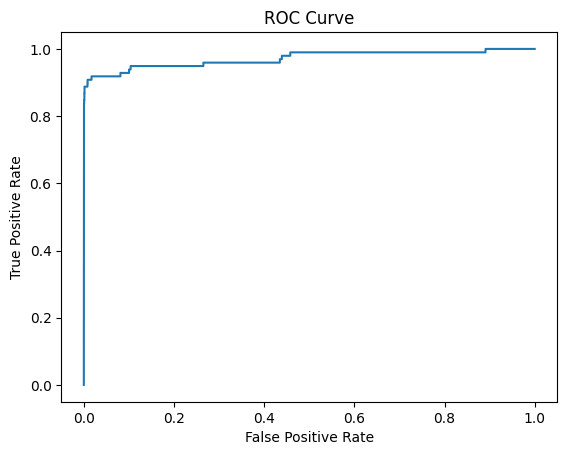

AUC: 0.9711624872233643


In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# Substitua 'modelo' pelo nome do seu modelo treinado (Ex: lr_base ou xgb_over)
y_probs = lr_base.predict_proba(X_test)[:, 1]

# Calcula as taxas de falsos positivos (fpr) e verdadeiros positivos (tpr)
fpr, tpr, _ = roc_curve(y_test, y_probs)

# Configura e exibe o gráfico da Curva ROC
plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

# Imprime o valor da área sob a curva (AUC)
print("AUC:", roc_auc_score(y_test, y_probs))


6 Ajuste do Limiar de Decisão (Threshold Tuning)

In [15]:
# Modificando o limiar do XGBoost para ser mais sensível a fraudes
limiar = 0.30
xgb_probs = xgb_over.predict_proba(X_test)[:, 1]
xgb_preds_custom = (xgb_probs >= limiar).astype(int)

print(f"\n--- XGBoost com Limiar customizado em {limiar} ---")
print(classification_report(y_test, xgb_preds_custom))



--- XGBoost com Limiar customizado em 0.3 ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.66      0.87      0.75        98

    accuracy                           1.00     56962
   macro avg       0.83      0.93      0.88     56962
weighted avg       1.00      1.00      1.00     56962



 7 Explique (Importância de Variáveis e SHAP)

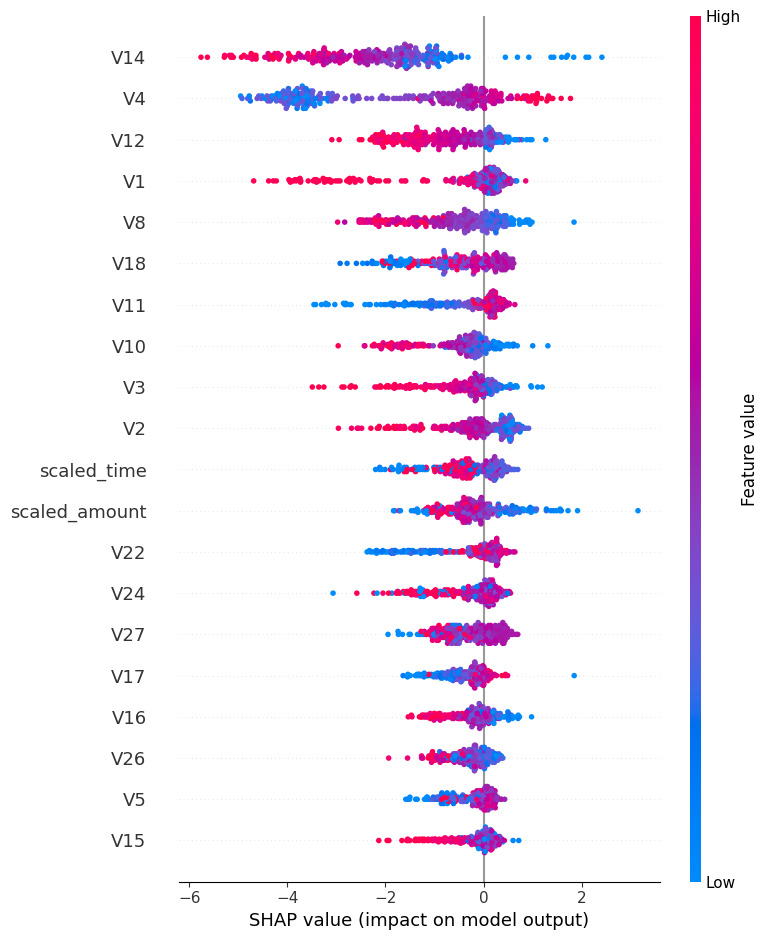

In [16]:
import shap

# Explicando o modelo campeão usando SHAP
explainer = shap.TreeExplainer(xgb_over)
# Usando uma amostra do teste para otimizar o tempo de cálculo
shap_values = explainer(X_test.iloc[:300])

# Gráfico de Resumo que mostra o impacto de cada variável na decisão de fraude
shap.summary_plot(shap_values, X_test.iloc[:300])
